In [ ]:
#pip install mlxtend

In [3]:
import pandas as pd

print(pd.__version__)

3.1.1


In [30]:

import random
from itertools import combinations
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [5]:
data = pd.read_csv("Fraudulent_online_shops_dataset.csv")

In [6]:
data.head()

,Online shop URL,Label,Domain length,Top domain length,Presence of prefix 'www',Number of digits,Number of letters,Number of dots (.),Number of hyphens (-),Presence of credit card payment,...,SSL certificate expire date,Issuer organization,SSL certificate issuer organization list item,Indication of young domain,Domain registration date,Presence of TrustPilot reviews,TrustPilot score,Presence of SiteJabber reviews,Presence in the standard Tranco list,Tranco List rank
0,https://www.allaccessorybest.com,fraudulent,24,3,1,0,27,2,0,1,...,Oct 11 03:53:36 2023 GMT,Google Trust Services LLC,9,1,2023-05-15 03:35,0,NaN,0,0,-1
1,https://www.b-watches.shop,fraudulent,18,4,1,0,20,2,1,0,...,Jun 16 23:59:59 2024 GMT,"Cloudflare, Inc.",1,1,2023-06-18 05:43,0,NaN,0,0,-1
2,https://www.waeschenamen-windrath.de,legitimate,28,2,1,0,30,2,1,1,...,Oct 24 21:53:20 2023 GMT,Let's Encrypt,2,2,Hidden,0,-1.0,0,0,-1
3,https://vendoprint.se,legitimate,13,2,0,0,17,1,0,1,...,Oct 9 15:13:00 2023 GMT,Google Trust Services LLC,9,1,2022-09-20 00:00,0,-1.0,0,0,-1
4,https://www.newbikeland.com,fraudulent,19,3,1,0,22,2,0,1,...,Oct 25 08:20:27 2023 GMT,Let's Encrypt,2,1,2023-07-27 09:05,0,NaN,0,0,-1


In [7]:
# number of unique SSL certificate issuer
len(data['SSL certificate issuer'].unique())

43

In [8]:
# 43 unique SSL cert issuer out of total rows, 1140
43/1140

0.037719298245614034

In [9]:
data.columns = data.columns.str.strip().str.replace(r'\s+', ' ', regex=True)
data.columns

Index(['Online shop URL', 'Label', 'Domain length', 'Top domain length',
       'Presence of prefix 'www'', 'Number of digits', 'Number of letters',
       'Number of dots (.)', 'Number of hyphens (-)',
       'Presence of credit card payment', 'Presence of money back payment',
       'Presence of cash on delivery payment', 'Presence of crypto currency',
       'Presence of free contact emails', 'Presence of logo URL',
       'SSL certificate issuer', 'SSL certificate expire date',
       'Issuer organization', 'SSL certificate issuer organization list item',
       'Indication of young domain', 'Domain registration date',
       'Presence of TrustPilot reviews', 'TrustPilot score',
       'Presence of SiteJabber reviews',
       'Presence in the standard Tranco list', 'Tranco List rank'],
      dtype='str')

In [10]:
data.isna().sum()

Online shop URL                                    0
Label                                              0
Domain length                                      0
Top domain length                                  0
Presence of prefix 'www'                           0
Number of digits                                   0
Number of letters                                  0
Number of dots (.)                                 0
Number of hyphens (-)                              0
Presence of credit card payment                    0
Presence of money back payment                     0
Presence of cash on delivery payment               0
Presence of crypto currency                        0
Presence of free contact emails                    0
Presence of logo URL                               0
SSL certificate issuer                             0
SSL certificate expire date                        0
Issuer organization                                0
SSL certificate issuer organization list item 

In [11]:
# every shop with a missing TrustPilot score is fraudulent
pd.crosstab(data['TrustPilot score'].isna(), data['Label'])

Label,fraudulent,legitimate
TrustPilot score,,
False,19,561
True,560,0


In [12]:
# Online shop URL: unique ID for each shop, not a feature
# SSL certificate expire date, Domain registration date: raw date text ("Hidden", blanks)
# Issuer organization, SSL certificate issuer organization list item: repeat the SSL issuer information
# TrustPilot score: missing = fraud, so it gives away the answer
data = data.drop(columns=['Online shop URL', 'SSL certificate expire date', 'Domain registration date',
                          'Issuer organization', 'SSL certificate issuer organization list item',
                          'TrustPilot score'])
data.shape

(1140, 20)

In [13]:
data.dtypes

Label                                     str
Domain length                           int64
Top domain length                       int64
Presence of prefix 'www'                int64
Number of digits                        int64
Number of letters                       int64
Number of dots (.)                      int64
Number of hyphens (-)                   int64
Presence of credit card payment         int64
Presence of money back payment          int64
Presence of cash on delivery payment    int64
Presence of crypto currency             int64
Presence of free contact emails         int64
Presence of logo URL                    int64
SSL certificate issuer                    str
Indication of young domain              int64
Presence of TrustPilot reviews          int64
Presence of SiteJabber reviews          int64
Presence in the standard Tranco list    int64
Tranco List rank                        int64
dtype: object

In [14]:
all_issuers = sorted(set(data['SSL certificate issuer']))
issuer_to_number = {issuer: i for i, issuer in enumerate(all_issuers)}
issuer_to_number

{'AlphaSSL CA - SHA256 - G4': 0,
 'Amazon RSA 2048 M01': 1,
 'Amazon RSA 2048 M02': 2,
 'Certum Domain Validation CA SHA2': 3,
 'Certum Organization Validation CA SHA2': 4,
 'Certyfikat SSL': 5,
 'Cloudflare Inc ECC CA-3': 6,
 'DigiCert EV RSA CA G2': 7,
 'DigiCert Global G2 TLS RSA SHA256 2020 CA1': 8,
 'DigiCert SHA2 Extended Validation Server CA': 9,
 'DigiCert TLS RSA SHA256 2020 CA1': 10,
 'Don Dominio / MrDomain RSA DV CA': 11,
 'E1': 12,
 'Encryption Everywhere DV TLS CA - G1': 13,
 'Encryption Everywhere DV TLS CA - G2': 14,
 'Encryption Everywhere G3 TLS ECC P384 SHA384 2023 CA1': 15,
 'GTS CA 1D4': 16,
 'GTS CA 1P5': 17,
 'GeoTrust EV RSA CA 2018': 18,
 'GeoTrust EV RSA CA G2': 19,
 'GeoTrust Global TLS RSA4096 SHA256 2022 CA1': 20,
 'GeoTrust RSA CA 2018': 21,
 'GeoTrust TLS RSA CA G1': 22,
 'GlobalSign Atlas R3 DV TLS CA 2023 Q2': 23,
 'GlobalSign Atlas R3 DV TLS CA 2023 Q3': 24,
 'GlobalSign Domain Validation CA - SHA256 - G3': 25,
 'GlobalSign RSA OV SSL CA 2018': 26,
 'G

In [15]:
data['SSL certificate issuer'] = data['SSL certificate issuer'].map(issuer_to_number)
data['SSL certificate issuer'].head()

0    17
1     6
2    29
3    17
4    12
Name: SSL certificate issuer, dtype: int64

In [16]:
data.dtypes

Label                                     str
Domain length                           int64
Top domain length                       int64
Presence of prefix 'www'                int64
Number of digits                        int64
Number of letters                       int64
Number of dots (.)                      int64
Number of hyphens (-)                   int64
Presence of credit card payment         int64
Presence of money back payment          int64
Presence of cash on delivery payment    int64
Presence of crypto currency             int64
Presence of free contact emails         int64
Presence of logo URL                    int64
SSL certificate issuer                  int64
Indication of young domain              int64
Presence of TrustPilot reviews          int64
Presence of SiteJabber reviews          int64
Presence in the standard Tranco list    int64
Tranco List rank                        int64
dtype: object

In [17]:
#exclude the target variable
column = data.columns[data.columns != 'Label']
column

Index(['Domain length', 'Top domain length', 'Presence of prefix 'www'',
       'Number of digits', 'Number of letters', 'Number of dots (.)',
       'Number of hyphens (-)', 'Presence of credit card payment',
       'Presence of money back payment',
       'Presence of cash on delivery payment', 'Presence of crypto currency',
       'Presence of free contact emails', 'Presence of logo URL',
       'SSL certificate issuer', 'Indication of young domain',
       'Presence of TrustPilot reviews', 'Presence of SiteJabber reviews',
       'Presence in the standard Tranco list', 'Tranco List rank'],
      dtype='str')

In [18]:
data['Label'] = data['Label'].map({'fraudulent': 1, 'legitimate': 0})
data['Label'].value_counts()

Label
1    579
0    561
Name: count, dtype: int64

In [20]:
data_scale = data[column]
data_scale.head()

,Domain length,Top domain length,Presence of prefix 'www',Number of digits,Number of letters,Number of dots (.),Number of hyphens (-),Presence of credit card payment,Presence of money back payment,Presence of cash on delivery payment,Presence of crypto currency,Presence of free contact emails,Presence of logo URL,SSL certificate issuer,Indication of young domain,Presence of TrustPilot reviews,Presence of SiteJabber reviews,Presence in the standard Tranco list,Tranco List rank
0,24,3,1,0,27,2,0,1,1,0,0,0,0,17,1,0,0,0,-1
1,18,4,1,0,20,2,1,0,1,0,0,1,0,6,1,0,0,0,-1
2,28,2,1,0,30,2,1,1,0,0,0,2,1,29,2,0,0,0,-1
3,13,2,0,0,17,1,0,1,0,0,0,2,1,17,1,0,0,0,-1
4,19,3,1,0,22,2,0,1,1,0,0,0,1,12,1,0,0,0,-1


In [21]:
scaler = StandardScaler()
scaled = scaler.fit_transform(data_scale)

In [22]:
data_scale[column] = scaled
data_scale.head()

,Domain length,Top domain length,Presence of prefix 'www',Number of digits,Number of letters,Number of dots (.),Number of hyphens (-),Presence of credit card payment,Presence of money back payment,Presence of cash on delivery payment,Presence of crypto currency,Presence of free contact emails,Presence of logo URL,SSL certificate issuer,Indication of young domain,Presence of TrustPilot reviews,Presence of SiteJabber reviews,Presence in the standard Tranco list,Tranco List rank
0,1.254702,0.200062,0.708503,-0.177401,1.241482,0.588357,-0.391341,0.557086,0.634203,-0.559789,-0.190693,-0.946033,-2.148433,-0.416468,0.572074,-0.536783,-0.200365,-0.12666,-0.114378
1,-0.075659,1.549596,0.708503,-0.177401,-0.384220,0.588357,2.087154,-1.795055,0.634203,-0.559789,-0.190693,-0.048050,-2.148433,-1.629313,0.572074,-0.536783,-0.200365,-0.12666,-0.114378
2,2.141609,-1.149471,0.708503,-0.177401,1.938211,0.588357,2.087154,0.557086,-1.576781,-0.559789,-0.190693,0.849933,0.465456,0.906635,2.078226,-0.536783,-0.200365,-0.12666,-0.114378
3,-1.184294,-1.149471,-1.411427,-0.177401,-1.080949,-1.431904,-0.391341,0.557086,-1.576781,-0.559789,-0.190693,0.849933,0.465456,-0.416468,0.572074,-0.536783,-0.200365,-0.12666,-0.114378
4,0.146067,0.200062,0.708503,-0.177401,0.080266,0.588357,-0.391341,0.557086,0.634203,-0.559789,-0.190693,-0.946033,0.465456,-0.967761,0.572074,-0.536783,-0.200365,-0.12666,-0.114378


In [23]:
data_scale.describe().loc[['mean', 'std']].round(2)

,Domain length,Top domain length,Presence of prefix 'www',Number of digits,Number of letters,Number of dots (.),Number of hyphens (-),Presence of credit card payment,Presence of money back payment,Presence of cash on delivery payment,Presence of crypto currency,Presence of free contact emails,Presence of logo URL,SSL certificate issuer,Indication of young domain,Presence of TrustPilot reviews,Presence of SiteJabber reviews,Presence in the standard Tranco list,Tranco List rank
mean,-0.0,0.0,0.0,0.0,0.0,0.0,-0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [25]:
X = data_scale      # scaled features
y = data['Label']   # target (1 = fraud, 0 = not fraud)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

In [26]:
print(X_train.shape, X_test.shape)
print(y_train.value_counts(), y_test.value_counts())

(912, 19) (228, 19)
Label
1    463
0    449
Name: count, dtype: int64 Label
1    116
0    112
Name: count, dtype: int64


In [28]:
models = {'Support Vector': SVC(random_state = 42),
          'Naive Bayes': GaussianNB(),
          'KNN': KNeighborsClassifier(n_neighbors = 5),
          'Logistic Regression': LogisticRegression(max_iter = 1000)}

In [29]:
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)      # training
    pred = model.predict(X_test)     # testing

    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    results[name] = {'Accuracy': accuracy_score(y_test, pred),
                     'Precision': precision_score(y_test, pred),
                     'Recall': recall_score(y_test, pred),
                     'Specificity': tn / (tn + fp),   # sklearn has no specificity function
                     'F1': f1_score(y_test, pred)}

results_d2 = pd.DataFrame(results).T.round(3)
results_d2

,Accuracy,Precision,Recall,Specificity,F1
Support Vector,0.925,0.946,0.905,0.946,0.925
Naive Bayes,0.754,0.695,0.922,0.580,0.793
KNN,0.873,0.866,0.888,0.857,0.877
Logistic Regression,0.904,0.879,0.940,0.866,0.908


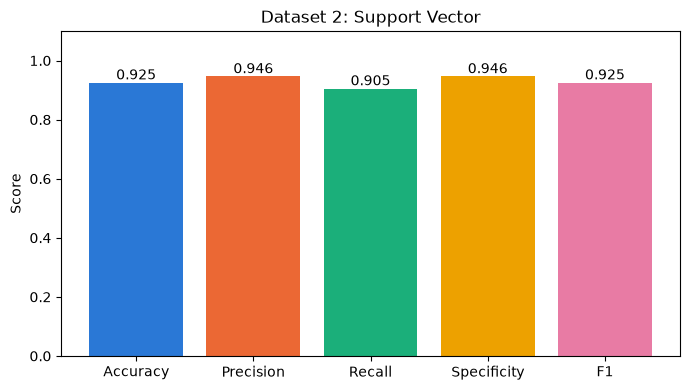

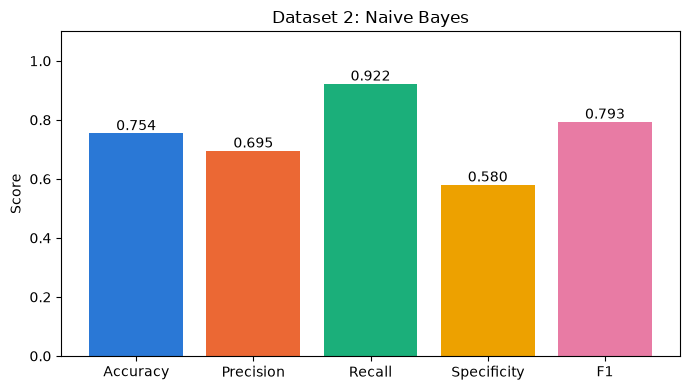

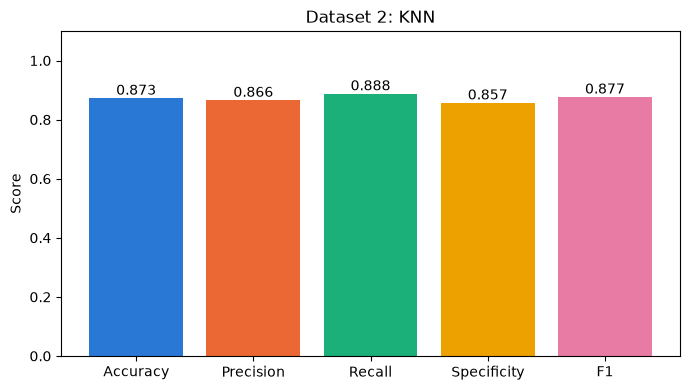

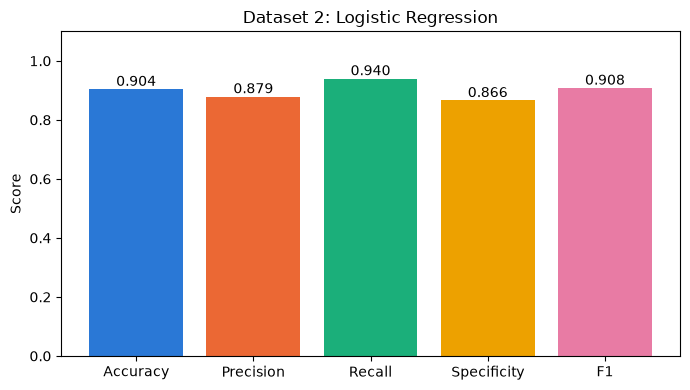

In [32]:
colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']

for name in results_d2.index:
    scores = results_d2.loc[name]

    plt.figure(figsize = (7, 4))
    bars = plt.bar(scores.index, scores.values, color = colors)
    plt.bar_label(bars, fmt = '%.3f')
    plt.ylim(0, 1.1)
    plt.title(f'Dataset 2: {name}')
    plt.ylabel('Score')
    plt.tight_layout()
    #plt.savefig(f'd2_{name}.png', dpi = 150)   # saves each graph for your report
    plt.show()

In [ ]:
one_hot_encoded_data = pd.DataFrame(0, index = data)
#one_hot_encoded_data

In [ ]:
for index, row in tx_data.iterrows():
    for item in row['Items']:
        one_hot_encoded_data.at[row['Transaction'], item] = 1

one_hot_encoded_data

In [ ]:
# Assign the one-hot encoded DataFrame (where each column represents an item and each row a transaction) to df
df = one_hot_encoded_data

